# Exploring Career Success

NFL career outcomes for each prospect. All data is taken from [here](https://www.kaggle.com/competitions/nfl-big-data-bowl-2027/data). These are the candidate target variables for predicting prospect success.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## player_career_successes.csv

In [2]:
df = pd.read_csv("../data/player_career_successes.csv")
df.head().style.format(precision=2).set_caption("First Rows")

,nfl_id,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,55867,0,1884,92,51,44,1,0,1
1,55870,2802,0,169,47,43,0,0,0
2,55874,3222,0,167,51,49,0,1,0
3,55875,3011,0,170,51,48,0,0,0
4,55877,0,1056,387,51,2,0,0,0


In [3]:
print(len(df)) # total number of players in dataset
df.describe().T.style.format(precision=2)

510


,count,mean,std,min,25%,50%,75%,max
nfl_id,510.00,57331.32,979.51,55867.00,56273.50,57290.00,58302.75,59278.00
career_offensive_snaps,510.00,327.42,632.40,0.00,0.00,0.00,361.75,3303.00
career_defensive_snaps,510.00,234.31,492.12,0.00,0.00,0.00,220.50,2666.00
career_special_teams_snaps,510.00,113.50,156.19,0.00,5.00,53.00,147.75,957.00
career_games_active,510.00,21.72,16.29,0.00,6.25,17.00,34.00,51.00
career_games_started,510.00,7.85,11.47,0.00,0.00,2.00,12.00,50.00
ap_all_pro_1st_team,510.00,0.01,0.11,0.00,0.00,0.00,0.00,1.00
ap_all_pro_2nd_team,510.00,0.00,0.06,0.00,0.00,0.00,0.00,1.00
pro_bowl_original_ballot,510.00,0.03,0.20,0.00,0.00,0.00,0.00,2.00


In [4]:
positions = pd.read_csv("../data/combine_results.csv", usecols=["nfl_id", "combine_position"])
df = df.merge(positions, on="nfl_id", how="left")

masks = {
    "TE": df["combine_position"] == "TE",
    "DB": df["combine_position"] == "DB",
    "WR": df["combine_position"] == "WR",
    "DL": df["combine_position"] == "DL",
    "OL": df["combine_position"] == "OL",
}

Players drafted earlier have had more seasons to accumulate snaps and games, so it's worth also looking at per-season rates.

In [5]:
draft_year = pd.read_csv("../data/players.csv", usecols=["nfl_id", "draft_year"])
df = df.merge(draft_year, on="nfl_id", how="left")
df["seasons"] = 2026 - df["draft_year"] # seasons played through 2025
print(df["seasons"].value_counts().sort_index())

seasons
1    173
2    177
3    160
Name: count, dtype: int64


### Snaps

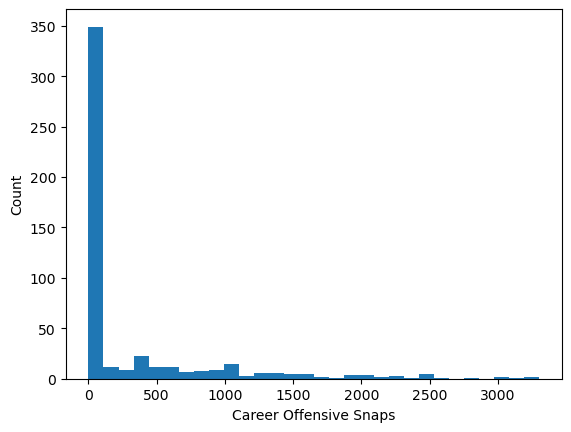

In [6]:
plt.hist(df["career_offensive_snaps"].dropna(), bins=30)
plt.xlabel("Career Offensive Snaps")
plt.ylabel("Count");

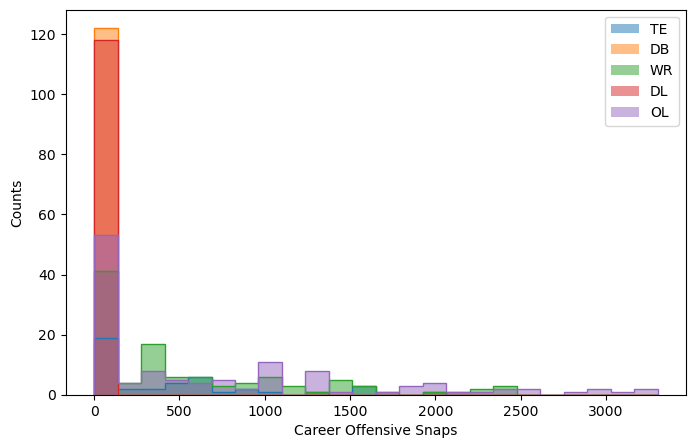

In [7]:
bins = np.linspace(df["career_offensive_snaps"].min(), df["career_offensive_snaps"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "career_offensive_snaps"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "career_offensive_snaps"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Career Offensive Snaps")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

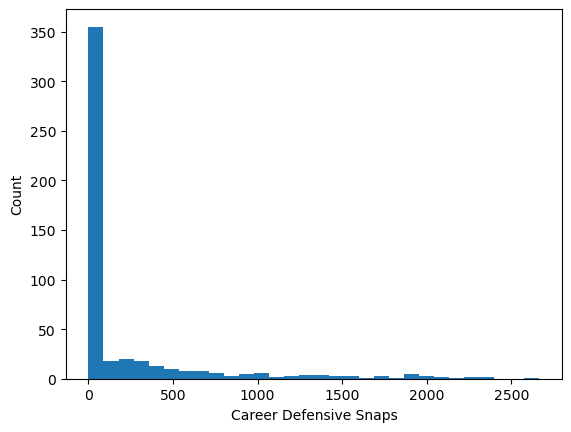

In [8]:
plt.hist(df["career_defensive_snaps"].dropna(), bins=30)
plt.xlabel("Career Defensive Snaps")
plt.ylabel("Count");

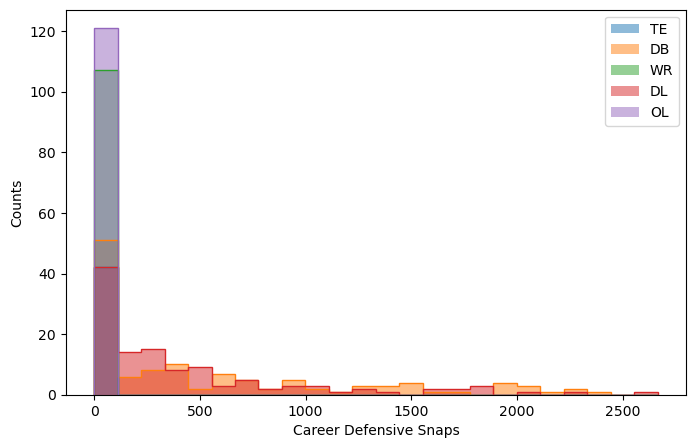

In [9]:
bins = np.linspace(df["career_defensive_snaps"].min(), df["career_defensive_snaps"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "career_defensive_snaps"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "career_defensive_snaps"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Career Defensive Snaps")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

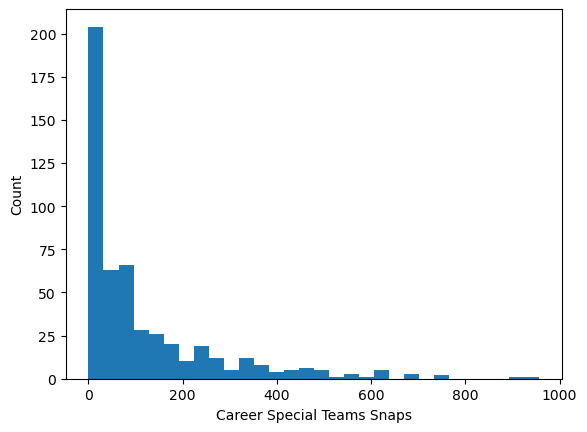

In [10]:
plt.hist(df["career_special_teams_snaps"].dropna(), bins=30)
plt.xlabel("Career Special Teams Snaps")
plt.ylabel("Count");

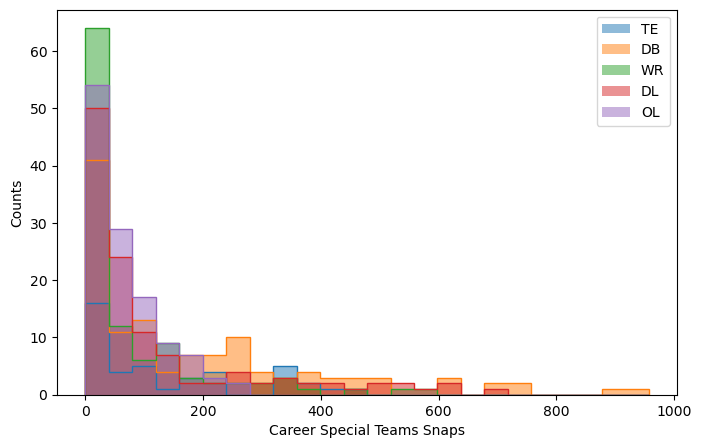

In [11]:
bins = np.linspace(df["career_special_teams_snaps"].min(), df["career_special_teams_snaps"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "career_special_teams_snaps"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "career_special_teams_snaps"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Career Special Teams Snaps")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

In [12]:
df["career_snaps"] = df["career_offensive_snaps"] + df["career_defensive_snaps"]
print((df["career_snaps"] == 0).mean()) # fraction with no offensive or defensive snaps

0.20588235294117646


### Games

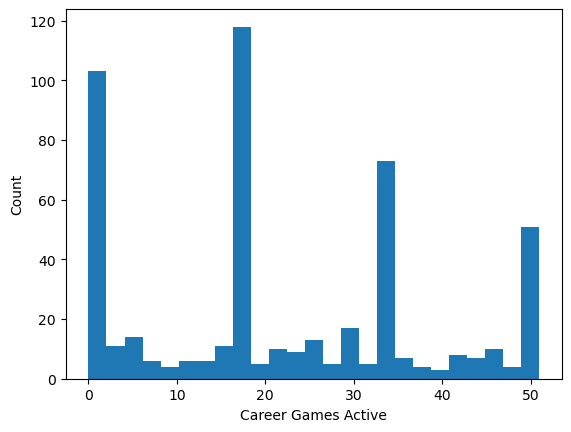

In [13]:
plt.hist(df["career_games_active"].dropna(), bins=25)
plt.xlabel("Career Games Active")
plt.ylabel("Count");

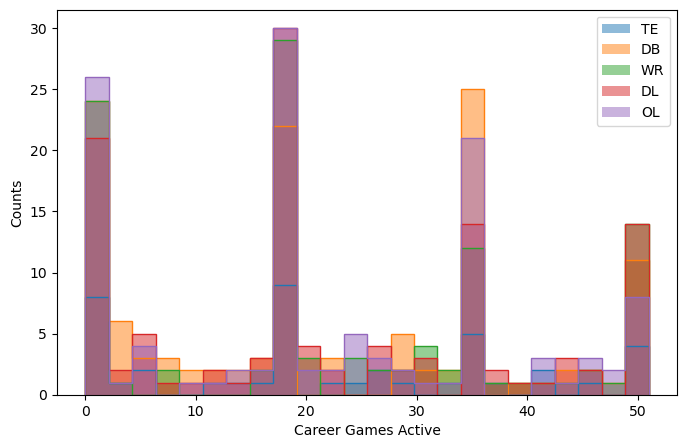

In [14]:
bins = np.linspace(df["career_games_active"].min(), df["career_games_active"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "career_games_active"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "career_games_active"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Career Games Active")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

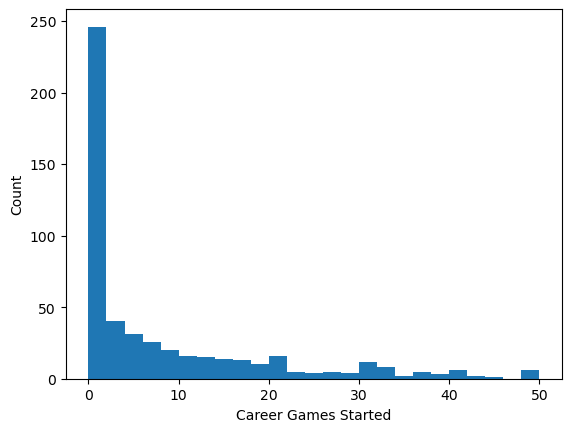

In [15]:
plt.hist(df["career_games_started"].dropna(), bins=25)
plt.xlabel("Career Games Started")
plt.ylabel("Count");

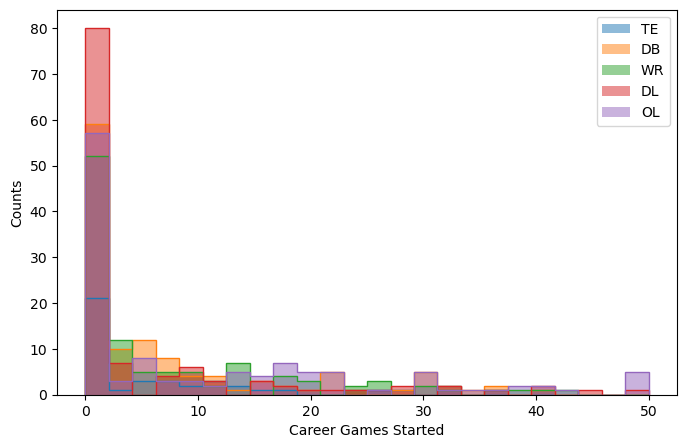

In [16]:
bins = np.linspace(df["career_games_started"].min(), df["career_games_started"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "career_games_started"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "career_games_started"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Career Games Started")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

In [17]:
df["starts_per_season"] = df["career_games_started"] / df["seasons"]

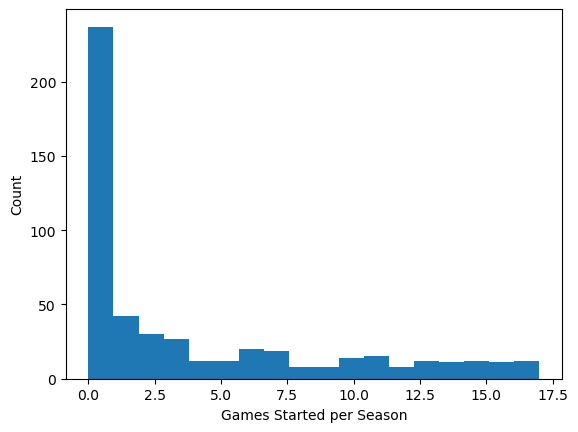

In [18]:
plt.hist(df["starts_per_season"].dropna(), bins=18)
plt.xlabel("Games Started per Season")
plt.ylabel("Count");

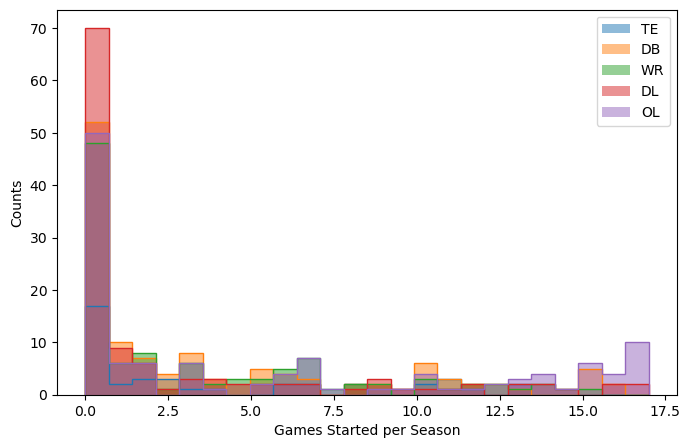

In [19]:
bins = np.linspace(df["starts_per_season"].min(), df["starts_per_season"].max(), 25)

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    color = f"C{i}"
    ax.hist(df.loc[m, "starts_per_season"], bins=bins, histtype="step", color=color)
    ax.hist(df.loc[m, "starts_per_season"], bins=bins, histtype="stepfilled", label=name, color=color, alpha=0.5)

ax.set_xlabel("Games Started per Season")
ax.set_ylabel("Counts")
ax.legend()
plt.show()

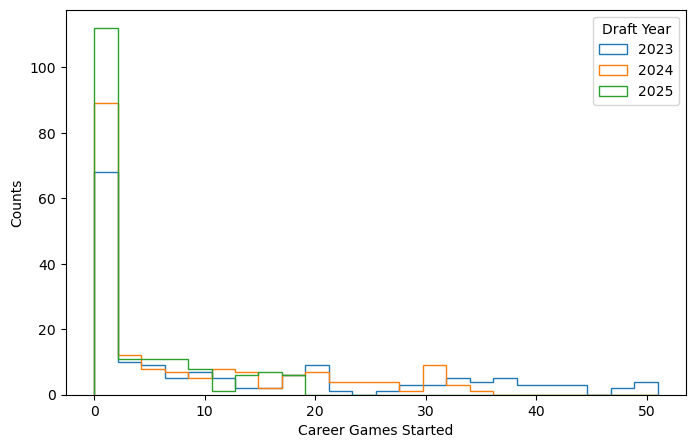

In [20]:
fig, ax = plt.subplots(figsize=(8,5))
for i, year in enumerate(sorted(df["draft_year"].unique())):
    m = df["draft_year"] == year
    ax.hist(df.loc[m, "career_games_started"], bins=np.linspace(0, 51, 25), histtype="step", lw=2, label=year, color=f"C{i}")
ax.set_xlabel("Career Games Started")
ax.set_ylabel("Counts")
ax.legend(title="Draft Year")
plt.show()

### Honors

In [21]:
honors = ["ap_all_pro_1st_team", "ap_all_pro_2nd_team", "pro_bowl_original_ballot"]
print(df[honors].sum())
df.loc[df[honors].sum(axis=1) > 0, ["nfl_id", "combine_position", "draft_year", "career_games_started"] + honors]

ap_all_pro_1st_team          6
ap_all_pro_2nd_team          2
pro_bowl_original_ballot    14
dtype: int64


,nfl_id,combine_position,draft_year,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,55867,DL,2023,44,1,0,1
2,55874,OL,2023,49,0,1,0
7,55884,WR,2023,36,1,0,1
18,55910,DB,2023,37,0,0,1
26,55919,DL,2023,36,0,0,1
32,55928,WR,2023,13,1,0,2
39,55942,DL,2023,49,0,0,1
85,56042,WR,2023,43,1,1,2
160,57126,OL,2024,22,0,0,1
166,57140,DL,2024,33,0,0,2


### Relationship to Draft Position

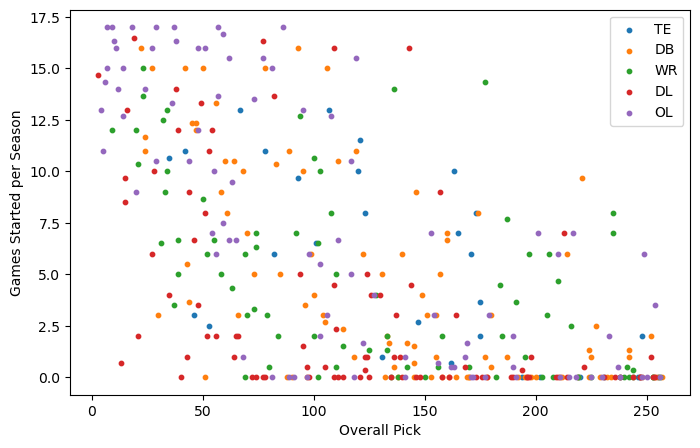

In [22]:
draft = pd.read_csv("../data/players.csv", usecols=["nfl_id", "draft_overall_pick"])
df = df.merge(draft, on="nfl_id", how="left")

fig, ax = plt.subplots(figsize=(8,5))
for i, (name, m) in enumerate(masks.items()):
    ax.scatter(df.loc[m, "draft_overall_pick"], df.loc[m, "starts_per_season"], s=10, label=name, color=f"C{i}")
ax.set_xlabel("Overall Pick")
ax.set_ylabel("Games Started per Season")
ax.legend()
plt.show()

In [23]:
undrafted = df["draft_overall_pick"].isna()
print(df.groupby(undrafted)["starts_per_season"].describe().rename(index={False: "drafted", True: "undrafted"}))

                    count      mean       std  min  25%  50%  75%        max
draft_overall_pick                                                          
drafted             383.0  5.009574  5.396393  0.0  0.0  3.0  9.0  17.000000
undrafted           127.0  0.375328  0.893334  0.0  0.0  0.0  0.0   5.666667
